In [1]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import copy
import shap
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import (roc_auc_score, average_precision_score,
                              classification_report, confusion_matrix,
                              ConfusionMatrixDisplay)
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


## 1. Load Data

In [2]:
eq_spectra       = np.load('eq_chemistry_spectra.npy')
eq_params        = np.load('eq_chemistry_params.npy')
wl_binned        = np.load('wl_binned.npy')
disequil_spectra = np.load('disequil_spectra_kaggle.npy')
disequil_params  = np.load('disequil_params_kaggle.npy')

print(f"Equilibrium spectra  : {eq_spectra.shape}")
print(f"Disequilibrium spectra: {disequil_spectra.shape}")
print(f"Wavelength grid      : {wl_binned.shape}  ({wl_binned.min():.2f}–{wl_binned.max():.2f} μm)")

Equilibrium spectra  : (113176, 52)
Disequilibrium spectra: (458, 52)
Wavelength grid      : (52,)  (0.55–7.28 μm)


In [3]:
# Column order for params arrays
param_names         = ["Rstar_Rs", "Rp_Rj", "Mp_Mj", "T", "log_met", "co_ratio"]
disequil_param_names = ["Rstar_Rs", "Rp_Rj", "Mp_Mj", "T", "log_Kzz"]

# Confirm column indices used later
T_COL_EQ      = param_names.index("T")           # 3
T_COL_DISEQ   = disequil_param_names.index("T")  # 3
KZZ_COL_DISEQ = disequil_param_names.index("log_Kzz")  # 4

print(f"eq_params   columns : {param_names}")
print(f"disequil_params cols: {disequil_param_names}")
print(f"T index (eq): {T_COL_EQ}  |  T index (diseq): {T_COL_DISEQ}  |  log_Kzz index: {KZZ_COL_DISEQ}")

eq_params   columns : ['Rstar_Rs', 'Rp_Rj', 'Mp_Mj', 'T', 'log_met', 'co_ratio']
disequil_params cols: ['Rstar_Rs', 'Rp_Rj', 'Mp_Mj', 'T', 'log_Kzz']
T index (eq): 3  |  T index (diseq): 3  |  log_Kzz index: 4


## 2. Normalisation
Row z-score only — one normalisation step is enough for spectra.

In [4]:
def row_zscore(spectra, epsilon=1e-8):
    mean = spectra.mean(axis=1, keepdims=True)
    std  = spectra.std(axis=1, keepdims=True)
    return (spectra - mean) / (std + epsilon)

eq_spectra_rn       = row_zscore(eq_spectra)
disequil_spectra_rn = row_zscore(disequil_spectra)

print(f"Row-normalised equilibrium    : mean={eq_spectra_rn.mean():.4f}, std={eq_spectra_rn.std():.4f}")
print(f"Row-normalised disequilibrium : mean={disequil_spectra_rn.mean():.4f}, std={disequil_spectra_rn.std():.4f}")

Row-normalised equilibrium    : mean=-0.0000, std=0.9879
Row-normalised disequilibrium : mean=0.0000, std=0.9992


## 3. Autoencoder — train on equilibrium only

In [5]:
# AE is trained ONLY on equilibrium spectra (unsupervised anomaly detection)
X_train_ae, X_val_ae = train_test_split(eq_spectra_rn, test_size=0.15, random_state=42)

print(f"AE train: {X_train_ae.shape}, AE val: {X_val_ae.shape}")
print(f"Disequil (will be used as anomalies): {disequil_spectra_rn.shape}")

AE train: (96199, 52), AE val: (16977, 52)
Disequil (will be used as anomalies): (458, 52)


In [6]:
class SpectrumAE(nn.Module):
    def __init__(self, input_dim=52, latent_dim=8):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 32), nn.ReLU(),
            nn.Linear(32, 16),        nn.ReLU(),
            nn.Linear(16, latent_dim)
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 16), nn.ReLU(),
            nn.Linear(16, 32),         nn.ReLU(),
            nn.Linear(32, input_dim)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

ae_model = SpectrumAE().to(device)
loss_fn  = nn.MSELoss()
opt_ae   = torch.optim.Adam(ae_model.parameters(), lr=1e-3)
print(ae_model)

SpectrumAE(
  (encoder): Sequential(
    (0): Linear(in_features=52, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=8, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=8, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=52, bias=True)
  )
)


Epoch   0 | train 0.20157 | val 0.02940
Epoch  10 | train 0.00264 | val 0.00256
Epoch  20 | train 0.00165 | val 0.00165
Epoch  30 | train 0.00136 | val 0.00134
Epoch  40 | train 0.00108 | val 0.00105
Epoch  50 | train 0.00093 | val 0.00091
Epoch  60 | train 0.00085 | val 0.00086
Epoch  70 | train 0.00080 | val 0.00080
Epoch  80 | train 0.00078 | val 0.00077
Epoch  90 | train 0.00075 | val 0.00075
Epoch  99 | train 0.00073 | val 0.00075


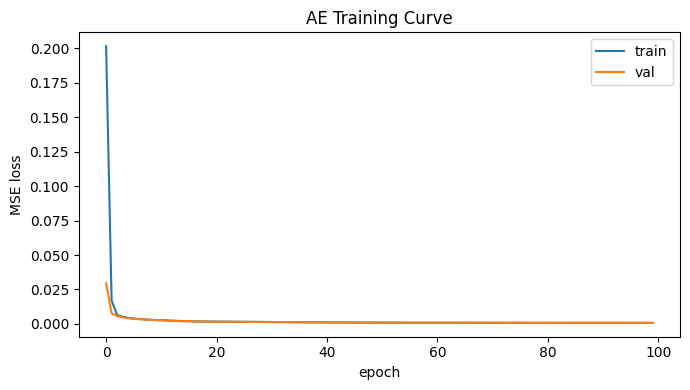

In [7]:
train_loader_ae = DataLoader(
    TensorDataset(torch.tensor(X_train_ae, dtype=torch.float32)),
    batch_size=256, shuffle=True
)
val_tensor_ae = torch.tensor(X_val_ae, dtype=torch.float32).to(device)

n_epochs_ae = 100
ae_history  = {"train_loss": [], "val_loss": []}

for epoch in range(n_epochs_ae):
    ae_model.train()
    train_loss = 0
    for (batch,) in train_loader_ae:
        batch = batch.to(device)
        opt_ae.zero_grad()
        recon = ae_model(batch)
        loss  = loss_fn(recon, batch)
        loss.backward()
        opt_ae.step()
        train_loss += loss.item() * batch.size(0)
    train_loss /= len(X_train_ae)

    ae_model.eval()
    with torch.no_grad():
        val_loss = loss_fn(ae_model(val_tensor_ae), val_tensor_ae).item()

    ae_history["train_loss"].append(train_loss)
    ae_history["val_loss"].append(val_loss)
    if epoch % 10 == 0 or epoch == n_epochs_ae - 1:
        print(f"Epoch {epoch:3d} | train {train_loss:.5f} | val {val_loss:.5f}")

plt.figure(figsize=(7, 4))
plt.plot(ae_history["train_loss"], label="train")
plt.plot(ae_history["val_loss"],   label="val")
plt.xlabel("epoch"); plt.ylabel("MSE loss"); plt.legend()
plt.title("AE Training Curve")
plt.tight_layout(); plt.show()

## 4. AE Reconstruction Error — Anomaly Detection

In [8]:
def reconstruction_error(model, X_np):
    """Compute per-spectrum MSE reconstruction error."""
    model.eval()
    with torch.no_grad():
        X_t   = torch.tensor(X_np, dtype=torch.float32).to(device)
        recon = model(X_t)
        return ((recon - X_t) ** 2).mean(dim=1).cpu().numpy()

val_errors   = reconstruction_error(ae_model, X_val_ae)
diseq_errors = reconstruction_error(ae_model, disequil_spectra_rn)

threshold_95 = np.percentile(val_errors, 95)
threshold_99 = np.percentile(val_errors, 99)

flagged_95 = (diseq_errors > threshold_95).sum()
flagged_99 = (diseq_errors > threshold_99).sum()

print(f"Equilibrium val error — 95th pct: {threshold_95:.5f}, 99th pct: {threshold_99:.5f}")
print(f"Disequil flagged @95th pct: {flagged_95}/{len(diseq_errors)} ({100*flagged_95/len(diseq_errors):.1f}%)")
print(f"Disequil flagged @99th pct: {flagged_99}/{len(diseq_errors)} ({100*flagged_99/len(diseq_errors):.1f}%)")

Equilibrium val error — 95th pct: 0.00192, 99th pct: 0.00433
Disequil flagged @95th pct: 189/458 (41.3%)
Disequil flagged @99th pct: 184/458 (40.2%)


In [9]:
y_true_ae = np.concatenate([np.zeros(len(val_errors)), np.ones(len(diseq_errors))])
y_score_ae = np.concatenate([val_errors, diseq_errors])

roc_auc_ae = roc_auc_score(y_true_ae, y_score_ae)
pr_auc_ae  = average_precision_score(y_true_ae, y_score_ae)

print(f"AE  ROC-AUC: {roc_auc_ae:.4f}")
print(f"AE  PR-AUC : {pr_auc_ae:.4f}  (baseline = {y_true_ae.mean():.4f})")

AE  ROC-AUC: 0.6705
AE  PR-AUC : 0.3245  (baseline = 0.0263)


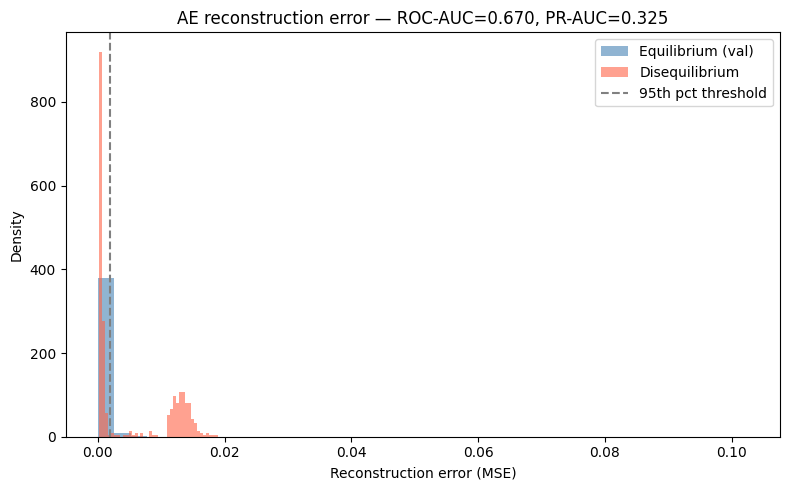

In [10]:
plt.figure(figsize=(8, 5))
plt.hist(val_errors,   bins=40, alpha=0.6, label="Equilibrium (val)", color="steelblue", density=True)
plt.hist(diseq_errors, bins=40, alpha=0.6, label="Disequilibrium",    color="tomato",    density=True)
plt.axvline(threshold_95, color="gray", linestyle="--", label="95th pct threshold")
plt.xlabel("Reconstruction error (MSE)"); plt.ylabel("Density"); plt.legend()
plt.title(f"AE reconstruction error — ROC-AUC={roc_auc_ae:.3f}, PR-AUC={pr_auc_ae:.3f}")
plt.tight_layout(); plt.show()

## 5. Param-Matched Equilibrium Subset
Filter equilibrium to the same T/Rp/Mp/Rstar ranges as disequilibrium, and near-solar Met/C-O (since disequilibrium dataset uses fixed solar composition).

Param-matched equilibrium subset: 1643
Median error — full-diversity val : 0.00047
Median error — param-matched      : 0.00036
Median error — disequilibrium     : 0.00084


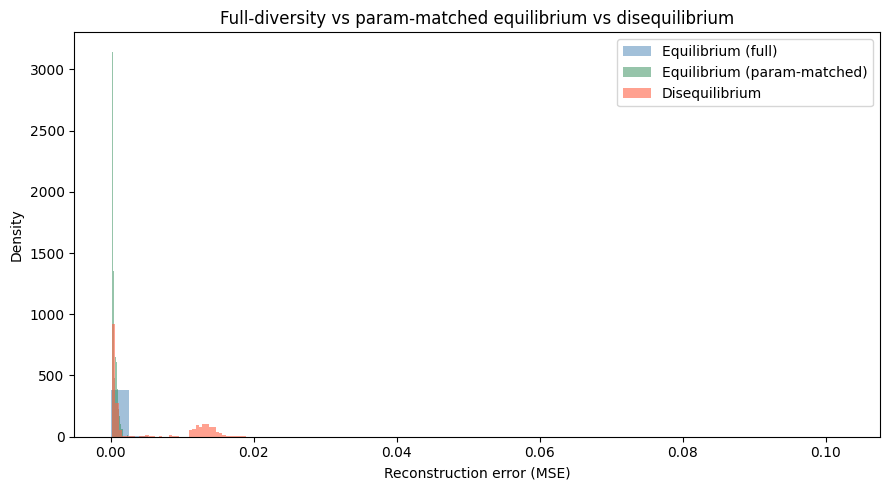

In [11]:
df_final_clean = pd.read_csv("df_final_clean.csv")
df_final_clean = df_final_clean[~df_final_clean["is_flat"]].reset_index(drop=True)

Rstar_c, Rp_c, Mp_c, T_c, log_met_c, co_c = eq_params.T

mask = (
    (T_c     >= df_final_clean["T"].min())       & (T_c     <= df_final_clean["T"].max()) &
    (Rp_c    >= df_final_clean["Rp_Rj"].min())   & (Rp_c    <= df_final_clean["Rp_Rj"].max()) &
    (Mp_c    >= df_final_clean["Mp_Mj"].min())   & (Mp_c    <= df_final_clean["Mp_Mj"].max()) &
    (Rstar_c >= df_final_clean["Rstar_Rs"].min()) & (Rstar_c <= df_final_clean["Rstar_Rs"].max()) &
    (np.abs(log_met_c) < 0.3) & (np.abs(co_c - 0.55) < 0.15)
)

eq_spectra_matched = eq_spectra[mask]
eq_params_matched  = eq_params[mask]
eq_matched_rn      = row_zscore(eq_spectra_matched)
matched_errors     = reconstruction_error(ae_model, eq_matched_rn)

print(f"Param-matched equilibrium subset: {mask.sum()}")
print(f"Median error — full-diversity val : {np.median(val_errors):.5f}")
print(f"Median error — param-matched      : {np.median(matched_errors):.5f}")
print(f"Median error — disequilibrium     : {np.median(diseq_errors):.5f}")

plt.figure(figsize=(9, 5))
plt.hist(val_errors,     bins=40, alpha=0.5, label="Equilibrium (full)",          color="steelblue", density=True)
plt.hist(matched_errors, bins=40, alpha=0.5, label="Equilibrium (param-matched)", color="seagreen",  density=True)
plt.hist(diseq_errors,   bins=40, alpha=0.6, label="Disequilibrium",              color="tomato",    density=True)
plt.xlabel("Reconstruction error (MSE)"); plt.ylabel("Density"); plt.legend()
plt.title("Full-diversity vs param-matched equilibrium vs disequilibrium")
plt.tight_layout(); plt.show()

## 6. AE SHAP — which wavelengths drive reconstruction error?

In [12]:
class ReconErrorWrapper(nn.Module):
    def __init__(self, ae_model):
        super().__init__()
        self.ae_model = ae_model
    def forward(self, x):
        recon = self.ae_model(x)
        return (recon - x) ** 2

wrapped_ae = ReconErrorWrapper(ae_model).to(device)
wrapped_ae.eval()

bg_idx_ae     = np.random.choice(len(X_train_ae), 100, replace=False)
background_ae = torch.tensor(X_train_ae[bg_idx_ae], dtype=torch.float32).to(device)

n_explain_ae   = min(100, len(disequil_spectra_rn))
explain_idx_ae = np.random.choice(len(disequil_spectra_rn), n_explain_ae, replace=False)
explain_samp_ae = torch.tensor(disequil_spectra_rn[explain_idx_ae], dtype=torch.float32).to(device)

explainer_ae   = shap.DeepExplainer(wrapped_ae, background_ae)
shap_vals_ae   = np.array(explainer_ae.shap_values(explain_samp_ae, check_additivity=False))

diag_shap_ae      = np.array([shap_vals_ae[b, :, b] for b in range(52)]).T   # (n_samples, 52)
mean_abs_shap_ae  = np.abs(diag_shap_ae).mean(axis=0)

importance_ae = pd.DataFrame({"wavelength_um": wl_binned, "mean_abs_shap": mean_abs_shap_ae}
                              ).sort_values("mean_abs_shap", ascending=False)
print("AE — Top 10 wavelengths driving reconstruction error:")
print(importance_ae.head(10).to_string(index=False))

AE — Top 10 wavelengths driving reconstruction error:
 wavelength_um  mean_abs_shap
      4.305458       0.002346
      0.550000       0.000914
      2.264002       0.000884
      2.219392       0.000735
      2.309508       0.000633
      1.405581       0.000618
      4.032167       0.000591
      3.370790       0.000591
      2.708080       0.000560
      3.438543       0.000551


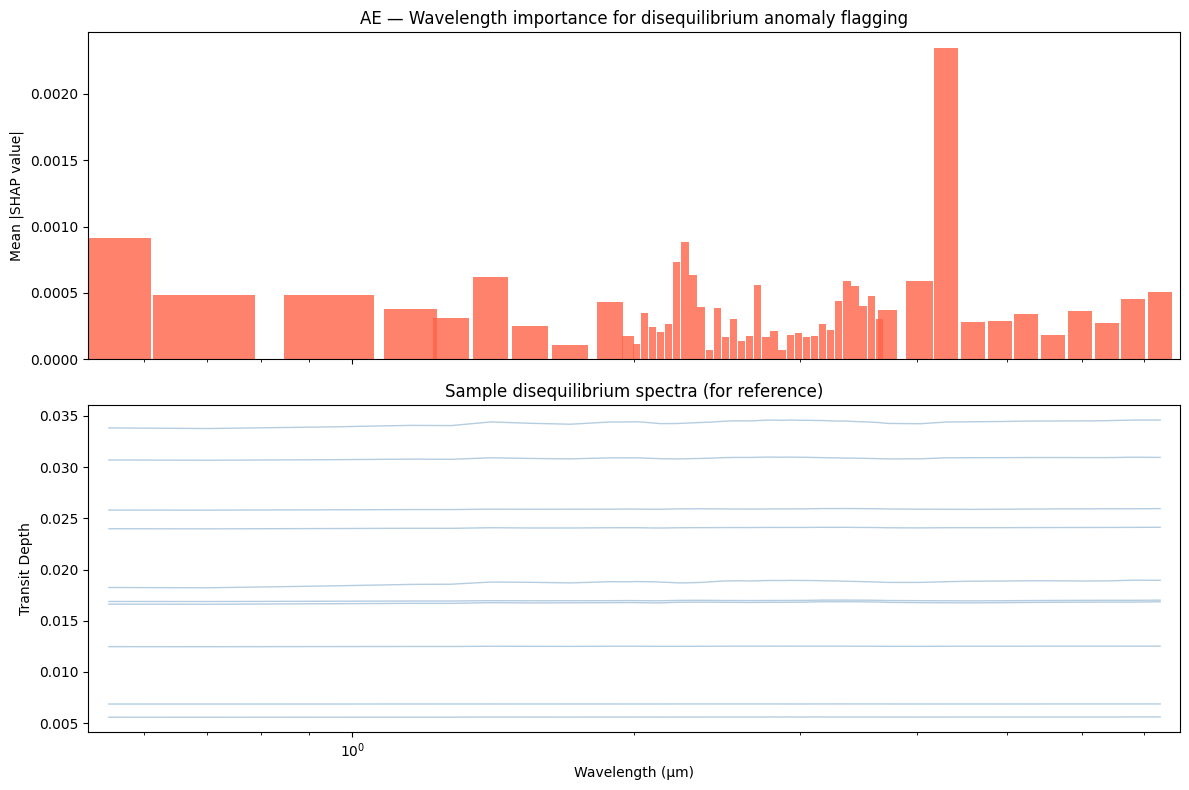

In [13]:
def log_bar_plot(ax, wl, importances, color, title):
    bin_edges  = np.sqrt(wl[:-1] * wl[1:])
    bin_widths = np.diff(np.concatenate([[wl[0]**2 / bin_edges[0]], bin_edges,
                                          [wl[-1]**2 / bin_edges[-1]]]))[:len(wl)]
    ax.bar(wl, importances, width=bin_widths * 0.9, color=color, alpha=0.8, align="center")
    ax.set_xscale("log")
    ticks = sorted(set(t for t in [wl.min(), 0.7, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, wl.max()]
                       if wl.min() <= t <= wl.max()))
    ax.set_xticks(ticks); ax.set_xticklabels([f"{t:g}" for t in ticks])
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.set_xlim(wl.min() * 0.95, wl.max() * 1.05)
    ax.set_title(title)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
log_bar_plot(axes[0], wl_binned, mean_abs_shap_ae, "tomato",
             "AE — Wavelength importance for disequilibrium anomaly flagging")
axes[0].set_ylabel("Mean |SHAP value|")

for i in range(min(10, n_explain_ae)):
    axes[1].plot(wl_binned, disequil_spectra[explain_idx_ae[i]], alpha=0.4, lw=1, color="steelblue")
axes[1].set_xlabel("Wavelength (μm)"); axes[1].set_ylabel("Transit Depth")
axes[1].set_title("Sample disequilibrium spectra (for reference)")
axes[1].set_xscale("log")

plt.tight_layout(); plt.show()

## 7. Reconstruction Error vs Physical Parameters

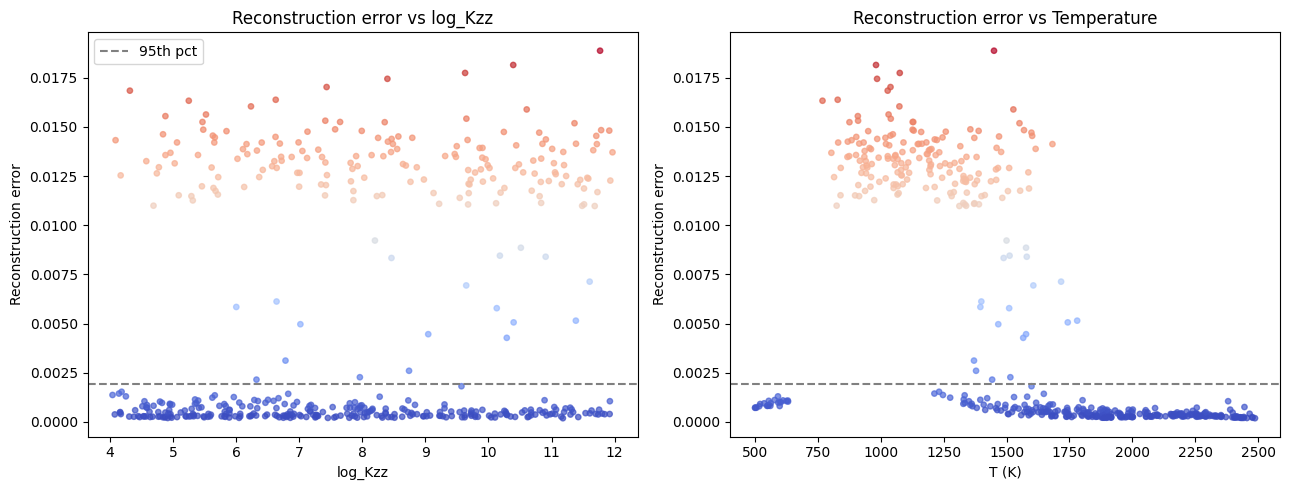

Correlation (log_Kzz vs error): r=0.175, p=0.0002
Correlation (T vs error)       : r=-0.633, p=0.0000


In [14]:
from scipy.stats import pearsonr

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Use verified column indices from Cell 2
axes[0].scatter(disequil_params[:, KZZ_COL_DISEQ], diseq_errors,
                c=diseq_errors, cmap="coolwarm", s=15, alpha=0.7)
axes[0].axhline(threshold_95, color="gray", linestyle="--", label="95th pct")
axes[0].set_xlabel("log_Kzz"); axes[0].set_ylabel("Reconstruction error")
axes[0].set_title("Reconstruction error vs log_Kzz"); axes[0].legend()

axes[1].scatter(disequil_params[:, T_COL_DISEQ], diseq_errors,
                c=diseq_errors, cmap="coolwarm", s=15, alpha=0.7)
axes[1].axhline(threshold_95, color="gray", linestyle="--")
axes[1].set_xlabel("T (K)"); axes[1].set_ylabel("Reconstruction error")
axes[1].set_title("Reconstruction error vs Temperature")

plt.tight_layout(); plt.show()

corr_kzz, p_kzz = pearsonr(disequil_params[:, KZZ_COL_DISEQ], diseq_errors)
corr_T,   p_T   = pearsonr(disequil_params[:, T_COL_DISEQ],   diseq_errors)
print(f"Correlation (log_Kzz vs error): r={corr_kzz:.3f}, p={p_kzz:.4f}")
print(f"Correlation (T vs error)       : r={corr_T:.3f}, p={p_T:.4f}")

Correlation (T vs error) — param-matched EQUILIBRIUM: r=-0.723, p=0.0000
Correlation (T vs error) — DISEQUILIBRIUM           : r=-0.633, p=0.0000


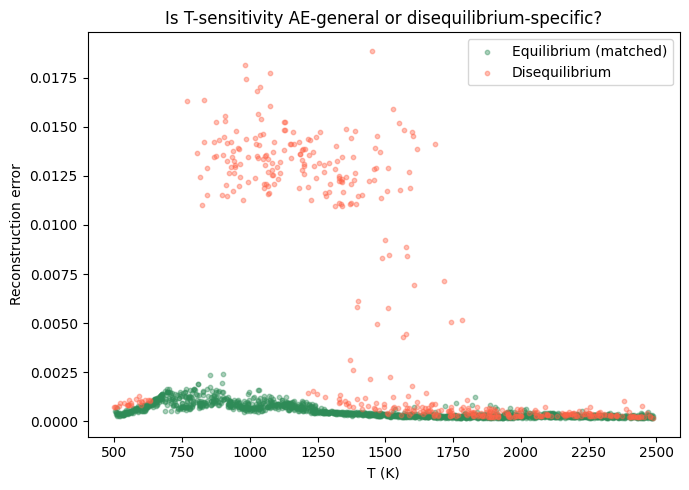

In [15]:
T_matched = eq_params[mask][:, T_COL_EQ]

corr_T_matched, p_T_matched = pearsonr(T_matched, matched_errors)
print(f"Correlation (T vs error) — param-matched EQUILIBRIUM: r={corr_T_matched:.3f}, p={p_T_matched:.4f}")
print(f"Correlation (T vs error) — DISEQUILIBRIUM           : r={corr_T:.3f}, p={p_T:.4f}")

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(T_matched,                       matched_errors, alpha=0.4, s=10, color="seagreen", label="Equilibrium (matched)")
ax.scatter(disequil_params[:, T_COL_DISEQ], diseq_errors,  alpha=0.4, s=10, color="tomato",   label="Disequilibrium")
ax.set_xlabel("T (K)"); ax.set_ylabel("Reconstruction error"); ax.legend()
ax.set_title("Is T-sensitivity AE-general or disequilibrium-specific?")
plt.tight_layout(); plt.show()

## 8. Classification Dataset (Equilibrium vs Disequilibrium)
Param-matched equilibrium at 2x disequilibrium count.

In [16]:
n_diseq     = len(disequil_spectra)
n_eq_sample = min(len(eq_spectra_matched), n_diseq * 2)

rng           = np.random.RandomState(42)
eq_sample_idx = rng.choice(len(eq_spectra_matched), n_eq_sample, replace=False)
eq_spectra_bal = eq_spectra_matched[eq_sample_idx]

X_eq    = row_zscore(eq_spectra_bal)
X_diseq = row_zscore(disequil_spectra)

X = np.concatenate([X_eq, X_diseq], axis=0)
y = np.concatenate([np.zeros(len(X_eq)), np.ones(len(X_diseq))])

print(f"Equilibrium (balanced sample): {len(X_eq)}")
print(f"Disequilibrium              : {len(X_diseq)}")
print(f"Total: {len(X)}  |  Class balance: {y.mean():.3f} positive")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,  stratify=y, random_state=42)
X_train, X_val,  y_train, y_val  = train_test_split(X_train, y_train, test_size=0.15, stratify=y_train, random_state=42)

print(f"Train: {len(X_train)}, Val: {len(X_val)}, Test: {len(X_test)}")

Equilibrium (balanced sample): 916
Disequilibrium              : 458
Total: 1374  |  Class balance: 0.333 positive
Train: 934, Val: 165, Test: 275


In [17]:
def build_balanced_set(ratio, seed=42):
    rng_   = np.random.RandomState(seed)
    n_eq   = min(len(eq_spectra_matched), int(len(disequil_spectra) * ratio))
    idx    = rng_.choice(len(eq_spectra_matched), n_eq, replace=False)
    X_eq_r = row_zscore(eq_spectra_matched[idx])
    X_d_r  = row_zscore(disequil_spectra)
    X_r    = np.concatenate([X_eq_r, X_d_r])
    y_r    = np.concatenate([np.zeros(len(X_eq_r)), np.ones(len(X_d_r))])
    return X_r, y_r

for ratio in [1, 2, 3, 5]:
    X_r, y_r = build_balanced_set(ratio)
    print(f"ratio={ratio}x  ->  total={len(X_r)}, pct_disequil={y_r.mean():.3f}")

ratio=1x  ->  total=916, pct_disequil=0.500
ratio=2x  ->  total=1374, pct_disequil=0.333
ratio=3x  ->  total=1832, pct_disequil=0.250
ratio=5x  ->  total=2101, pct_disequil=0.218


## 9. XGBoost Classifier

In [18]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

xgb_model.fit(
    X_train, y_train,
    eval_set=[(X_val, y_val)],
    verbose=50,
)

print("XGBoost training done!")

[0]	validation_0-logloss:0.56454
[50]	validation_0-logloss:0.13980
[100]	validation_0-logloss:0.13292
[150]	validation_0-logloss:0.12914
[199]	validation_0-logloss:0.12266
XGBoost training done!


XGBoost  ROC-AUC: 0.9982
XGBoost  PR-AUC : 0.9966

                precision    recall  f1-score   support

   Equilibrium       0.99      0.96      0.98       183
Disequilibrium       0.93      0.98      0.95        92

      accuracy                           0.97       275
     macro avg       0.96      0.97      0.96       275
  weighted avg       0.97      0.97      0.97       275



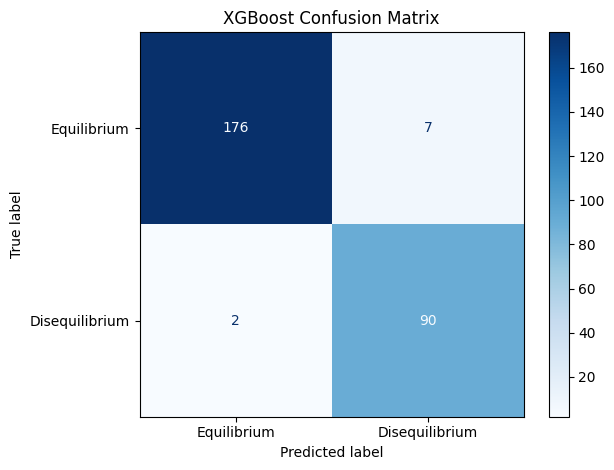

In [19]:
xgb_probs = xgb_model.predict_proba(X_test)[:, 1]
xgb_preds = (xgb_probs > 0.5).astype(int)

xgb_roc = roc_auc_score(y_test, xgb_probs)
xgb_pr  = average_precision_score(y_test, xgb_probs)

print(f"XGBoost  ROC-AUC: {xgb_roc:.4f}")
print(f"XGBoost  PR-AUC : {xgb_pr:.4f}")
print()
print(classification_report(y_test, xgb_preds, target_names=["Equilibrium", "Disequilibrium"]))

cm = confusion_matrix(y_test, xgb_preds)
ConfusionMatrixDisplay(cm, display_labels=["Equilibrium", "Disequilibrium"]).plot(cmap="Blues")
plt.title("XGBoost Confusion Matrix")
plt.tight_layout(); plt.show()

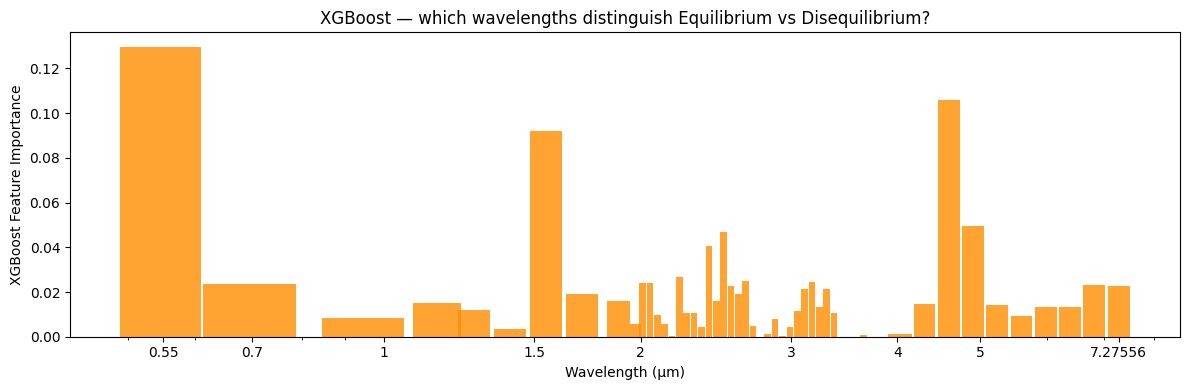


Top 10 most important wavelength bins (XGBoost):
  1. 0.550 μm — importance 0.1296
  2. 4.597 μm — importance 0.1057
  3. 1.550 μm — importance 0.0921
  4. 4.909 μm — importance 0.0494
  5. 2.501 μm — importance 0.0468
  6. 2.403 μm — importance 0.0406
  7. 2.219 μm — importance 0.0268
  8. 2.655 μm — importance 0.0250
  9. 3.175 μm — importance 0.0245
  10. 2.050 μm — importance 0.0242


In [20]:
importances_xgb = xgb_model.feature_importances_
top_idx_xgb     = np.argsort(importances_xgb)[::-1]

fig, ax = plt.subplots(figsize=(12, 4))
bin_edges  = np.sqrt(wl_binned[:-1] * wl_binned[1:])
bin_widths = np.diff(np.concatenate([[wl_binned[0]**2 / bin_edges[0]], bin_edges,
                                      [wl_binned[-1]**2 / bin_edges[-1]]]))[:len(wl_binned)]
ax.bar(wl_binned, importances_xgb, width=bin_widths * 0.9, color="darkorange", alpha=0.8)
ax.set_xscale("log")
ticks = sorted(set(t for t in [wl_binned.min(), 0.7, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, wl_binned.max()]
                   if wl_binned.min() <= t <= wl_binned.max()))
ax.set_xticks(ticks); ax.set_xticklabels([f"{t:g}" for t in ticks])
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlabel("Wavelength (μm)"); ax.set_ylabel("XGBoost Feature Importance")
ax.set_title("XGBoost — which wavelengths distinguish Equilibrium vs Disequilibrium?")
plt.tight_layout(); plt.show()

print("\nTop 10 most important wavelength bins (XGBoost):")
for rank, i in enumerate(top_idx_xgb[:10]):
    print(f"  {rank+1}. {wl_binned[i]:.3f} μm — importance {importances_xgb[i]:.4f}")

## 10. CNN Binary Classifier

In [21]:
class SpectrumCNN(nn.Module):
    def __init__(self, input_len=52):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=5, padding=2), nn.ReLU(), nn.BatchNorm1d(16),
            nn.Conv1d(16, 32, kernel_size=5, padding=2), nn.ReLU(), nn.BatchNorm1d(32),
            nn.MaxPool1d(2),
            nn.Conv1d(32, 32, kernel_size=3, padding=1), nn.ReLU(), nn.BatchNorm1d(32),
            nn.AdaptiveAvgPool1d(1)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(32, 16), nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        x = x.unsqueeze(1)   # (batch, 1, 52)
        return self.classifier(self.conv(x)).squeeze(-1)

cnn_model = SpectrumCNN().to(device)
print(cnn_model)

SpectrumCNN(
  (conv): Sequential(
    (0): Conv1d(1, 16, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): ReLU()
    (2): BatchNorm1d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Conv1d(16, 32, kernel_size=(5,), stride=(1,), padding=(2,))
    (4): ReLU()
    (5): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Conv1d(32, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (8): ReLU()
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): AdaptiveAvgPool1d(output_size=1)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Dropout(p=0.3, inplace=False)
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Dropout(p=0.2, inplace=False)
    (5): Linear(in_features=16, out_features=1, bias=True)
  )
)


Epoch   0 | train 0.8770 | val 0.8989
Epoch  10 | train 0.1746 | val 0.4586
Epoch  20 | train 0.1338 | val 0.3071
Epoch  30 | train 0.1168 | val 0.2796
Epoch  40 | train 0.0792 | val 0.1530
Epoch  50 | train 0.0852 | val 0.2263
Epoch  60 | train 0.1722 | val 0.1371
Epoch  70 | train 0.1155 | val 0.1588
Epoch  80 | train 0.0896 | val 0.7494
Epoch  90 | train 0.0307 | val 0.1696
Epoch  99 | train 0.1287 | val 0.2893


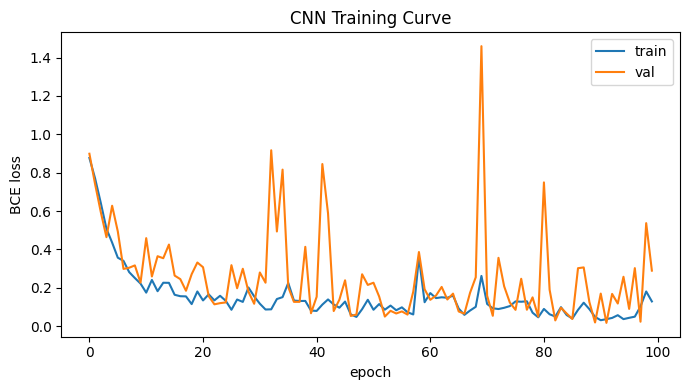

In [22]:
train_ds_cnn = TensorDataset(torch.tensor(X_train, dtype=torch.float32),
                             torch.tensor(y_train, dtype=torch.float32))
train_loader_cnn = DataLoader(train_ds_cnn, batch_size=32, shuffle=True)

val_X_cnn = torch.tensor(X_val, dtype=torch.float32).to(device)
val_y_cnn = torch.tensor(y_val, dtype=torch.float32).to(device)

pos_weight = torch.tensor([(y_train == 0).sum() / (y_train == 1).sum()],
                           dtype=torch.float32).to(device)
loss_fn_cnn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
opt_cnn     = torch.optim.Adam(cnn_model.parameters(), lr=1e-3, weight_decay=1e-4)

n_epochs_cnn = 100
cnn_history  = {"train_loss": [], "val_loss": []}

for epoch in range(n_epochs_cnn):
    cnn_model.train()
    train_loss = 0
    for xb, yb in train_loader_cnn:
        xb, yb = xb.to(device), yb.to(device)
        opt_cnn.zero_grad()
        loss = loss_fn_cnn(cnn_model(xb), yb)
        loss.backward(); opt_cnn.step()
        train_loss += loss.item() * xb.size(0)
    train_loss /= len(X_train)

    cnn_model.eval()
    with torch.no_grad():
        val_loss = loss_fn_cnn(cnn_model(val_X_cnn), val_y_cnn).item()

    cnn_history["train_loss"].append(train_loss)
    cnn_history["val_loss"].append(val_loss)
    if epoch % 10 == 0 or epoch == n_epochs_cnn - 1:
        print(f"Epoch {epoch:3d} | train {train_loss:.4f} | val {val_loss:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(cnn_history["train_loss"], label="train")
plt.plot(cnn_history["val_loss"],   label="val")
plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.legend()
plt.title("CNN Training Curve")
plt.tight_layout(); plt.show()

CNN  ROC-AUC: 0.9971
CNN  PR-AUC : 0.9943

                precision    recall  f1-score   support

   Equilibrium       1.00      0.90      0.95       183
Disequilibrium       0.83      1.00      0.91        92

      accuracy                           0.93       275
     macro avg       0.91      0.95      0.93       275
  weighted avg       0.94      0.93      0.93       275



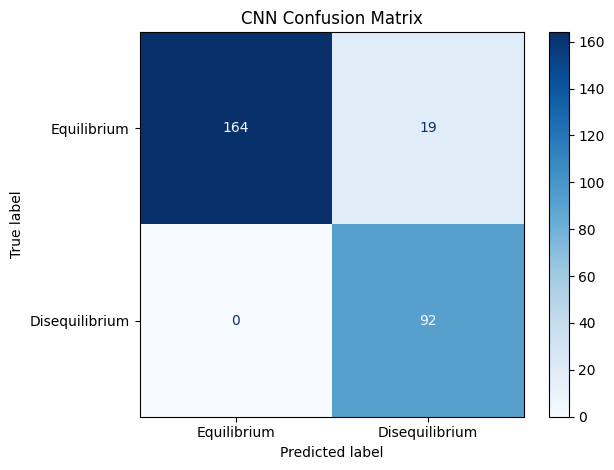

In [23]:
cnn_model.eval()
with torch.no_grad():
    test_logits = cnn_model(torch.tensor(X_test, dtype=torch.float32).to(device))
    test_probs  = torch.sigmoid(test_logits).cpu().numpy()

test_preds = (test_probs > 0.5).astype(int)

cnn_roc = roc_auc_score(y_test, test_probs)
cnn_pr  = average_precision_score(y_test, test_probs)

print(f"CNN  ROC-AUC: {cnn_roc:.4f}")
print(f"CNN  PR-AUC : {cnn_pr:.4f}")
print()
print(classification_report(y_test, test_preds, target_names=["Equilibrium", "Disequilibrium"]))

cm = confusion_matrix(y_test, test_preds)
ConfusionMatrixDisplay(cm, display_labels=["Equilibrium", "Disequilibrium"]).plot(cmap="Blues")
plt.title("CNN Confusion Matrix")
plt.tight_layout(); plt.show()

## 11. Model Comparison Summary

In [24]:
print("=" * 45)
print(f"{'Model':<20} {'ROC-AUC':>10} {'PR-AUC':>10}")
print("=" * 45)
print(f"{'AE (anomaly)':<20} {roc_auc_ae:>10.4f} {pr_auc_ae:>10.4f}")
print(f"{'XGBoost':<20} {xgb_roc:>10.4f} {xgb_pr:>10.4f}")
print(f"{'CNN':<20} {cnn_roc:>10.4f} {cnn_pr:>10.4f}")
print("=" * 45)

Model                   ROC-AUC     PR-AUC
AE (anomaly)             0.6705     0.3245
XGBoost                  0.9982     0.9966
CNN                      0.9971     0.9943


## 12. CNN Ratio Sensitivity Analysis (5 seeds × 3 ratios)

In [25]:
def train_and_eval_cnn(ratio, seed, n_epochs=100, patience=15):
    X_r, y_r = build_balanced_set(ratio, seed=seed)
    Xtr, Xte, ytr, yte = train_test_split(X_r, y_r, test_size=0.2,  stratify=y_r, random_state=seed)
    Xtr, Xva, ytr, yva = train_test_split(Xtr, ytr, test_size=0.15, stratify=ytr, random_state=seed)

    torch.manual_seed(seed)
    m   = SpectrumCNN().to(device)
    opt_ = torch.optim.Adam(m.parameters(), lr=1e-3, weight_decay=1e-4)
    pw   = torch.tensor([(ytr==0).sum()/(ytr==1).sum()], dtype=torch.float32).to(device)
    lf   = nn.BCEWithLogitsLoss(pos_weight=pw)
    tl   = DataLoader(TensorDataset(torch.tensor(Xtr, dtype=torch.float32),
                                     torch.tensor(ytr, dtype=torch.float32)),
                       batch_size=32, shuffle=True)
    Xva_t = torch.tensor(Xva, dtype=torch.float32).to(device)
    yva_t = torch.tensor(yva, dtype=torch.float32).to(device)

    best_val, best_state, bad = float("inf"), None, 0
    for epoch in range(n_epochs):
        m.train()
        for xb, yb in tl:
            xb, yb = xb.to(device), yb.to(device)
            opt_.zero_grad(); lf(m(xb), yb).backward(); opt_.step()
        m.eval()
        with torch.no_grad():
            vloss = lf(m(Xva_t), yva_t).item()
        if vloss < best_val:
            best_val, best_state, bad = vloss, copy.deepcopy(m.state_dict()), 0
        else:
            bad += 1
            if bad >= patience: break

    m.load_state_dict(best_state); m.eval()
    with torch.no_grad():
        probs = torch.sigmoid(m(torch.tensor(Xte, dtype=torch.float32).to(device))).cpu().numpy()
    return roc_auc_score(yte, probs), average_precision_score(yte, probs)

results = []
for ratio in [1, 2, 3]:
    for seed in [0, 1, 42, 7, 99]:
        auc, pr = train_and_eval_cnn(ratio, seed)
        results.append({"ratio": ratio, "seed": seed, "roc_auc": auc, "pr_auc": pr})
        print(f"ratio={ratio} seed={seed}  ROC-AUC={auc:.4f}  PR-AUC={pr:.4f}")

results_df = pd.DataFrame(results)
print()
print(results_df.groupby("ratio")[["roc_auc","pr_auc"]].agg(["mean","std"]))

ratio=1 seed=0  ROC-AUC=0.9989  PR-AUC=0.9989
ratio=1 seed=1  ROC-AUC=0.9999  PR-AUC=0.9999
ratio=1 seed=42  ROC-AUC=1.0000  PR-AUC=1.0000
ratio=1 seed=7  ROC-AUC=0.9998  PR-AUC=0.9998
ratio=1 seed=99  ROC-AUC=1.0000  PR-AUC=1.0000
ratio=2 seed=0  ROC-AUC=1.0000  PR-AUC=1.0000
ratio=2 seed=1  ROC-AUC=1.0000  PR-AUC=1.0000
ratio=2 seed=42  ROC-AUC=0.9990  PR-AUC=0.9981
ratio=2 seed=7  ROC-AUC=0.9996  PR-AUC=0.9993
ratio=2 seed=99  ROC-AUC=0.9998  PR-AUC=0.9996
ratio=3 seed=0  ROC-AUC=1.0000  PR-AUC=1.0000
ratio=3 seed=1  ROC-AUC=0.9985  PR-AUC=0.9955
ratio=3 seed=42  ROC-AUC=0.9996  PR-AUC=0.9990
ratio=3 seed=7  ROC-AUC=0.9966  PR-AUC=0.9920
ratio=3 seed=99  ROC-AUC=1.0000  PR-AUC=1.0000

        roc_auc              pr_auc          
           mean       std      mean       std
ratio                                        
1      0.999716  0.000447  0.999719  0.000444
2      0.999703  0.000394  0.999412  0.000785
3      0.998941  0.001466  0.997281  0.003503


## 13. CNN Confidence vs log_Kzz

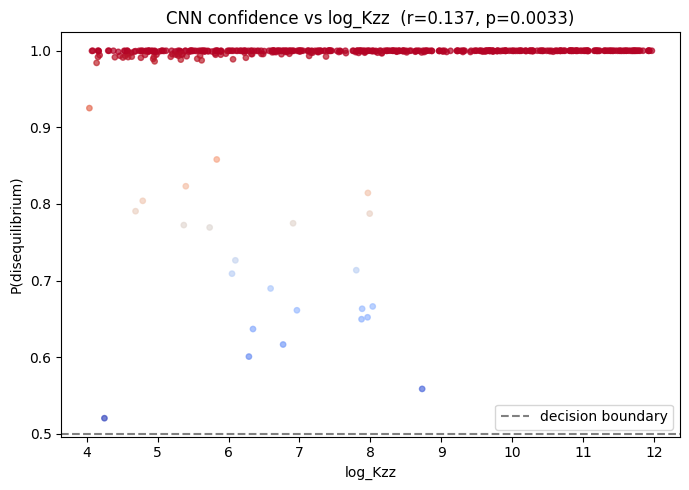

Correlation (log_Kzz vs CNN confidence): r=0.137, p=0.0033


In [26]:
X_diseq_all = row_zscore(disequil_spectra)
cnn_model.eval()
with torch.no_grad():
    all_diseq_probs = torch.sigmoid(
        cnn_model(torch.tensor(X_diseq_all, dtype=torch.float32).to(device))
    ).cpu().numpy()

from scipy.stats import pearsonr
corr_kzz_cnn, p_kzz_cnn = pearsonr(disequil_params[:, KZZ_COL_DISEQ], all_diseq_probs)

plt.figure(figsize=(7, 5))
plt.scatter(disequil_params[:, KZZ_COL_DISEQ], all_diseq_probs,
            c=all_diseq_probs, cmap="coolwarm", s=15, alpha=0.7)
plt.axhline(0.5, color="gray", linestyle="--", label="decision boundary")
plt.xlabel("log_Kzz"); plt.ylabel("P(disequilibrium)")
plt.title(f"CNN confidence vs log_Kzz  (r={corr_kzz_cnn:.3f}, p={p_kzz_cnn:.4f})")
plt.legend(); plt.tight_layout(); plt.show()
print(f"Correlation (log_Kzz vs CNN confidence): r={corr_kzz_cnn:.3f}, p={p_kzz_cnn:.4f}")

## 14. False Positive Analysis — which equilibrium spectra fool the CNN?

19 false positives out of 183 equilibrium test samples
        Rstar_Rs      Rp_Rj      Mp_Mj            T    log_met   co_ratio
count  19.000000  19.000000  19.000000    19.000000  19.000000  19.000000
mean    1.253895   1.232440   2.917013  2043.486995   0.091665   0.441525
std     0.397407   0.408663   1.007412   231.556817   0.139777   0.031787
min     0.606526   0.628830   1.481719  1560.080124  -0.263738   0.401921
25%     0.918562   0.867293   1.991016  1932.059314   0.026533   0.411856
50%     1.231889   1.320894   3.124278  2042.859428   0.123086   0.445882
75%     1.561763   1.455766   3.525475  2205.291048   0.173329   0.466292
max     1.934213   1.882317   4.747322  2399.452573   0.282598   0.503697


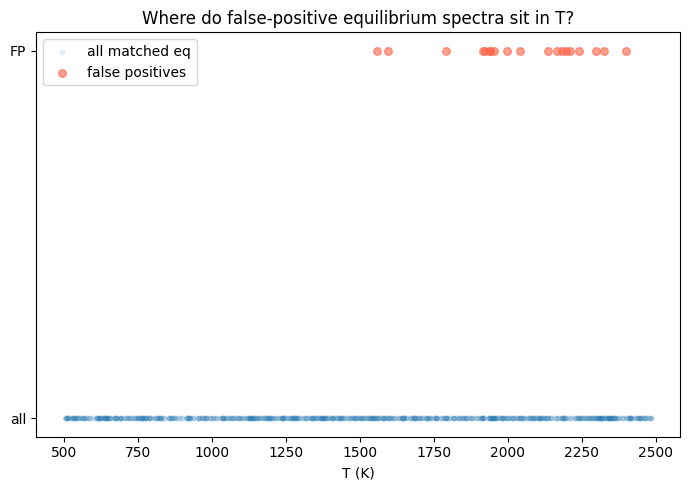

In [27]:
fp_mask    = (y_test == 0) & (test_preds == 1)
print(f"{fp_mask.sum()} false positives out of {(y_test==0).sum()} equilibrium test samples")

orig_idx = np.arange(len(X))
_, idx_test, _, _ = train_test_split(orig_idx, y, test_size=0.2, stratify=y, random_state=42)

fp_orig_idx  = idx_test[np.where(fp_mask)[0]]
eq_positions = fp_orig_idx[fp_orig_idx < len(X_eq)]
fp_eq_params = eq_params_matched[eq_sample_idx][eq_positions]

fp_df = pd.DataFrame(fp_eq_params, columns=param_names)
print(fp_df.describe())

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(eq_params_matched[eq_sample_idx][:, T_COL_EQ],
           np.zeros(len(eq_sample_idx)), alpha=0.1, s=10, label="all matched eq")
ax.scatter(fp_eq_params[:, T_COL_EQ], np.ones(len(fp_eq_params)),
           alpha=0.6, s=30, color="tomato", label="false positives")
ax.set_xlabel("T (K)"); ax.set_yticks([0,1]); ax.set_yticklabels(["all","FP"])
ax.set_title("Where do false-positive equilibrium spectra sit in T?")
ax.legend(); plt.tight_layout(); plt.show()

## 15. CNN SHAP — compare against AE SHAP

In [28]:
class CNNProbWrapper(nn.Module):
    def __init__(self, cnn):
        super().__init__()
        self.cnn = cnn
    def forward(self, x):
        return torch.sigmoid(self.cnn(x)).unsqueeze(-1)

wrapped_cnn = CNNProbWrapper(cnn_model).to(device)
wrapped_cnn.eval()

bg_idx_cnn     = np.random.choice(len(X_train), min(100, len(X_train)), replace=False)
background_cnn = torch.tensor(X_train[bg_idx_cnn], dtype=torch.float32).to(device)

diseq_test_idx  = np.where(y_test == 1)[0]
n_explain_cnn   = min(100, len(diseq_test_idx))
explain_idx_cnn = np.random.choice(diseq_test_idx, n_explain_cnn, replace=False)
explain_samp_cnn = torch.tensor(X_test[explain_idx_cnn], dtype=torch.float32).to(device)

explainer_cnn   = shap.DeepExplainer(wrapped_cnn, background_cnn)
shap_vals_cnn   = np.array(explainer_cnn.shap_values(explain_samp_cnn, check_additivity=False)).squeeze()
mean_abs_shap_cnn = np.abs(shap_vals_cnn).mean(axis=0)

importance_cnn = pd.DataFrame({"wavelength_um": wl_binned, "mean_abs_shap": mean_abs_shap_cnn}
                               ).sort_values("mean_abs_shap", ascending=False)
print("CNN — Top 10 wavelength bins:")
print(importance_cnn.head(10).to_string(index=False))

CNN — Top 10 wavelength bins:
 wavelength_um  mean_abs_shap
      2.654720       0.111364
      3.370790       0.107644
      4.597272       0.099494
      3.304372       0.092376
      2.708080       0.086118
      2.874681       0.080228
      3.438543       0.068891
      2.932462       0.065970
      3.507657       0.065750
      2.818039       0.064917


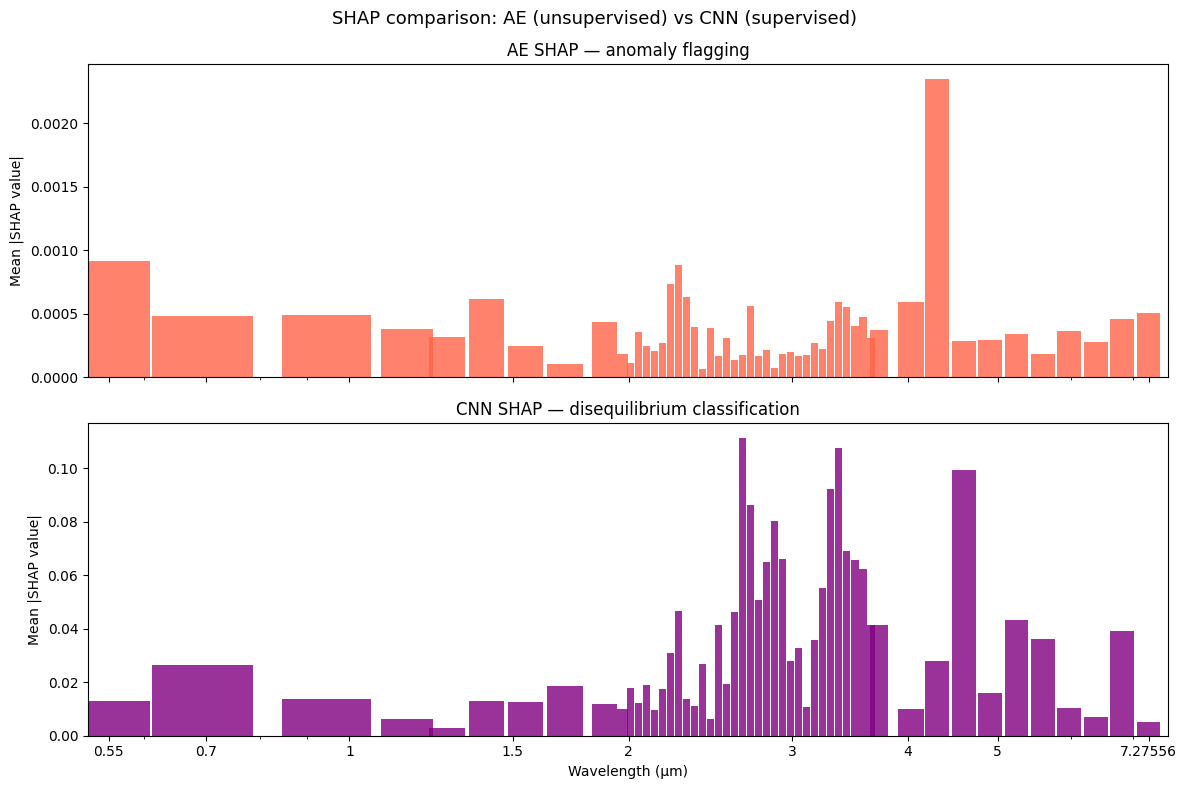

In [29]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
log_bar_plot(axes[0], wl_binned, mean_abs_shap_ae,  "tomato",  "AE SHAP — anomaly flagging")
log_bar_plot(axes[1], wl_binned, mean_abs_shap_cnn, "purple",  "CNN SHAP — disequilibrium classification")

axes[0].set_ylabel("Mean |SHAP value|")


for ax in axes:
    ax.set_ylabel("Mean |SHAP value|")
axes[1].set_xlabel("Wavelength (μm)")

plt.suptitle("SHAP comparison: AE (unsupervised) vs CNN (supervised)", fontsize=13)
plt.tight_layout(); plt.show()